In [4]:
import pandas as pd

df = pd.read_csv('IPLPlayerStat.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,NaN,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0.1         605 non-null    int64  
 1   Unnamed: 0           605 non-null    int64  
 2   player               605 non-null    object 
 3   runs                 605 non-null    int64  
 4   boundaries           605 non-null    int64  
 5   balls_faced          605 non-null    int64  
 6   wickets              598 non-null    float64
 7   balls_bowled         605 non-null    int64  
 8   runs_conceded        605 non-null    int64  
 9   matches              605 non-null    int64  
 10  batting_avg          605 non-null    float64
 11  batting_strike_rate  605 non-null    float64
 12  boundaries_percent   605 non-null    float64
 13  bowling_economy      605 non-null    float64
 14  bowling_avg          605 non-null    float64
 15  bowling_strike_rate  605 non-null    flo

In [7]:
# there are better ways , we have also seen them , but right now , just do it , im tired !!
df = df.dropna()

In [8]:
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0
5,5,5,A Dananjaya,4,0,5,0.0,25,47,1,4.00,80.00,0.00,11.28,470000.00,250000.00,0,0,Poor,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 598 entries, 1 to 604
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0.1         598 non-null    int64  
 1   Unnamed: 0           598 non-null    int64  
 2   player               598 non-null    object 
 3   runs                 598 non-null    int64  
 4   boundaries           598 non-null    int64  
 5   balls_faced          598 non-null    int64  
 6   wickets              598 non-null    float64
 7   balls_bowled         598 non-null    int64  
 8   runs_conceded        598 non-null    int64  
 9   matches              598 non-null    int64  
 10  batting_avg          598 non-null    float64
 11  batting_strike_rate  598 non-null    float64
 12  boundaries_percent   598 non-null    float64
 13  bowling_economy      598 non-null    float64
 14  bowling_avg          598 non-null    float64
 15  bowling_strike_rate  598 non-null    float64


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7,5)
NAVY_BLUE = '#004BAO'
GOLD = '#D1AB3E'

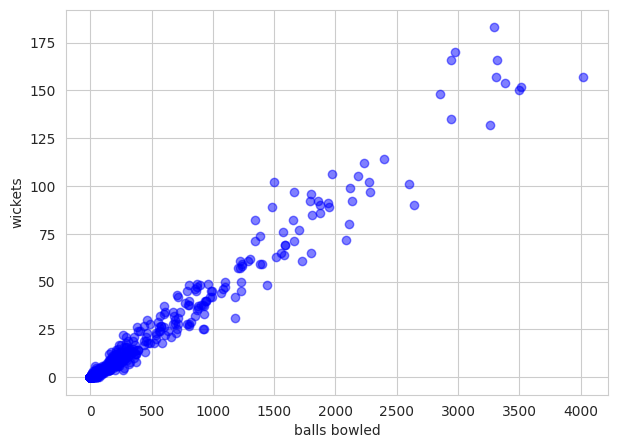

In [23]:
x = df[['balls_bowled']]
y = df[['wickets']]

plt.scatter( x , y , color = 'blue' , alpha = 0.5)
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.show()

why 42 is taken as random state ? <br>
The number 42 is used as a default random_state in machine learning primarily as a pop culture reference to Douglas Adams' The Hitchhiker's Guide to the Galaxy, where 42 is the "Answer to the Ultimate Question of Life, the Universe, and Everything."

In [25]:
x_train , x_test , y_train , y_test = train_test_split( x , y , test_size = 0.2 , random_state = 42)
model = LinearRegression()
model.fit( x_train , y_train )

print("intercept : " , round(model.intercept_.item() , 2))
print("slope : " , round(model.coef_[0].item() , 4))

print(f"the equation will be y = {round(model.coef_[0].item() , 4)}x + {round(model.intercept_.item() , 2)}" )

intercept :  -0.56
slope :  0.0467
the equation will be y = 0.0467x + -0.56


In [26]:
# checking what model actually predicted
print(model.predict(x_train))

[[-5.64315258e-01]
 [ 1.39981808e+01]
 [ 5.55876746e-01]
 [ 4.24554108e-02]
 [ 1.62610320e+02]
 [ 1.61918901e+01]
 [-5.64315258e-01]
 [ 2.37618875e+00]
 [-2.84267257e-01]
 [-5.64315258e-01]
 [ 2.35198128e+01]
 [ 7.83712478e+00]
 [ 5.55876746e-01]
 [ 8.69973598e+01]
 [ 3.62153222e+01]
 [ 2.13261035e+01]
 [ 4.21896796e+01]
 [ 2.45933302e+01]
 [ 1.18044715e+01]
 [ 3.99492956e+01]
 [-5.64315258e-01]
 [ 3.25280235e+01]
 [-5.64315258e-01]
 [ 1.05442555e+01]
 [ 7.64488851e+01]
 [-5.64315258e-01]
 [ 3.63640476e+00]
 [ 1.11597275e+00]
 [ 6.87008904e+01]
 [-4.21925603e-03]
 [ 1.36659205e+02]
 [ 4.56989810e+00]
 [ 6.48735677e+01]
 [-5.64315258e-01]
 [ 1.22712181e+01]
 [ 7.34617064e+01]
 [-5.64315258e-01]
 [ 9.37738878e+00]
 [ 1.76941808e+00]
 [-2.37592590e-01]
 [-5.64315258e-01]
 [ 3.94825489e+01]
 [ 1.13377248e+01]
 [ 2.79626076e+00]
 [ 1.08243035e+01]
 [ 2.65623675e+00]
 [-5.64315258e-01]
 [ 7.29016104e+01]
 [-5.64315258e-01]
 [-2.84267257e-01]
 [ 7.99494851e+01]
 [ 8.49057011e+00]
 [ 2.1428154

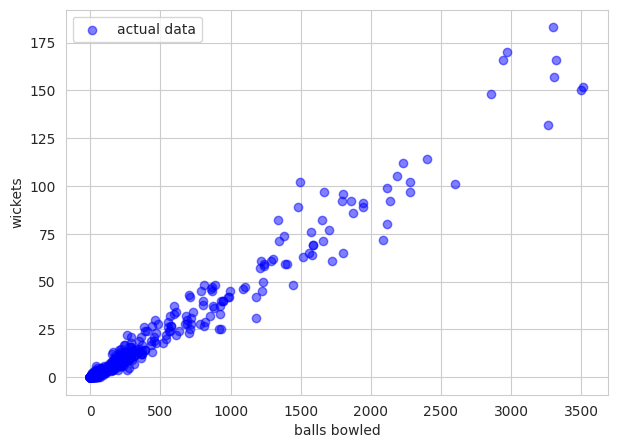

In [28]:
plt.scatter(x_train , y_train , color = 'blue' , alpha = 0.5 , label = 'actual data')
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.legend()
plt.show()

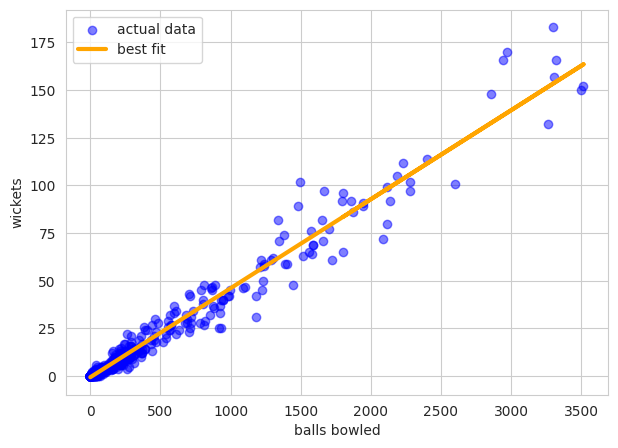

In [36]:
plt.scatter(x_train , y_train , color = 'blue' , alpha = 0.5 , label = 'actual data')
plt.plot(x_train , model.predict(x_train) , color = 'orange' , linewidth = 3 , label = 'best fit')
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.legend()
plt.show()

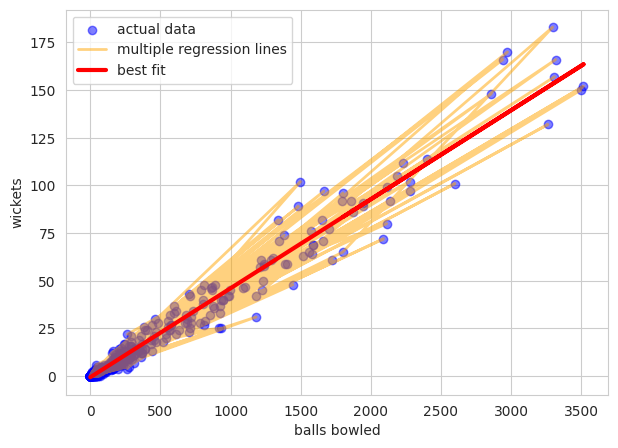

In [42]:
plt.scatter(x_train , y_train , color = 'blue' , alpha = 0.5 , label = 'actual data')
plt.plot(x_train , y_train , color = 'orange' , linewidth = 2 , label = 'multiple regression lines' , alpha = 0.5)
plt.plot(x_train , model.predict(x_train) , color = 'red' , linewidth = 3 , label = 'best fit')
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.legend()
plt.show()

In [39]:
# predictions on testing data

y_pred = model.predict(x_test)
comparison = pd.DataFrame({
    'balls_bowled' : x_test['balls_bowled'].values ,
    'actual_wickets' : y_test['wickets'].values,
    'predicted_wickets' : np.round(y_pred , 1).flatten()
})

comparison.head(10)

,balls_bowled,actual_wickets,predicted_wickets
0,0,0.0,-0.6
1,873,35.0,40.2
2,211,10.0,9.3
3,150,7.0,6.4
4,0,0.0,-0.6
5,13,0.0,0.0
6,0,0.0,-0.6
7,18,0.0,0.3
8,0,0.0,-0.6
9,57,3.0,2.1
